# Los móviles de ahora no aguantan nada: pongo la frase a prueba

**Categoría: EDA (análisis exploratorio de datos).** Describo resultados existentes; no entreno un modelo ni hago predicciones.

La pregunta es si los móviles actuales aguantan menos que los antiguos. Para responder sin hacer trampas, comparo autonomía con autonomía y documentos con documentos. No hay un único marcador para una carga, una batería envejecida, una caída y una reparación.

## Mi ruta y mi glosario

Primero reviso el panel; comparo sus extremos y sus años intermedios; compruebo una segunda tarea, el vídeo; después separo los máximos anunciados por Nokia y los ciclos declarados por Apple. Termino con reparación, resistencia y límites.

**Mediana:** valor central de un grupo, que no representa al mercado si el grupo no lo representa. **Cambio porcentual:** diferencia respecto al valor inicial; duplicar supone un 100 % más. **Índice 2015 = 100:** comparación de cada familia con su propio punto de partida. **Capacidad al 80 %:** queda cuatro quintas partes de la energía inicial; no significa que la batería deje de funcionar.

In [1]:
# cargo los datos ya preparados y configuro gráficos legibles
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

raiz = Path.cwd()
datos = pd.read_csv(raiz / 'data/processed/autonomia.csv')
declaraciones = pd.read_csv(raiz / 'data/processed/declaraciones.csv')
resultados = raiz / 'resultados'
resultados.mkdir(exist_ok=True)
colores = {'iPhone':'#446ddf','Galaxy S':'#d85a30','Moto G':'#397a69'}
plt.rcParams.update({'figure.figsize':(10,5),'axes.spines.top':False,'axes.spines.right':False,'font.size':11})
assert len(datos) == 12
display(datos[['modelo','anio','familia','wifi_original','video_original']])

,modelo,anio,familia,wifi_original,video_original
0,Samsung Galaxy S6,2015,Galaxy S,7h 55min,NaN
1,Samsung Galaxy S9,2018,Galaxy S,7h 54min,10h 9min
2,Samsung Galaxy S21,2021,Galaxy S,9h 04min,15h 41min
3,Samsung Galaxy S25,2025,Galaxy S,18h 02min,26h 30min
4,Motorola Moto G (2015),2015,Moto G,8h 46min,11h 17min
5,Motorola Moto G6,2018,Moto G,9h 13min,10h 00min
6,Motorola Moto G30,2021,Moto G,17h 49min,22h 29min
7,Motorola Moto G86,2025,Moto G,17h 18min,20h 08min
8,Apple iPhone 6s,2015,iPhone,8h 12min,11h 39min
9,Apple iPhone XR,2018,iPhone,15h 10min,16h 51min


## 1. Comparo tres familias durante una década

Trabajo con doce modelos seleccionados por fecha y familia: 2015, 2018, 2021 y 2025. Uso la prueba wifi v1.3 de Notebookcheck, con una tarea de navegación y brillo de referencia común. Los dispositivos se probaron en fechas distintas y con su software de entonces. No interpreto la diferencia como un efecto aislado de la batería ni como un estudio de envejecimiento.

Empiezo con horas absolutas. Cada línea conecta observaciones concretas; no interpolo resultados de los años sin datos. El panel contiene dos familias de gama alta y una más económica, pero no igualo precios, tamaños, capacidades ni prestaciones. No afirmo que sean todos los móviles.

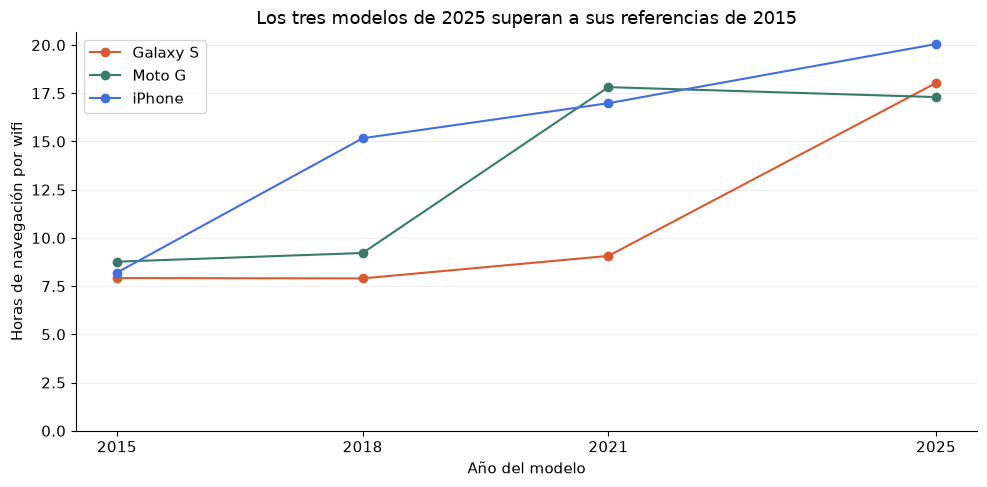

In [2]:
# dibujo las doce mediciones sin mezclar tareas ni versiones de prueba
figura, eje = plt.subplots()
for familia, grupo in datos.groupby('familia'):
    eje.plot(grupo['anio'], grupo['wifi_horas'], marker='o', label=familia, color=colores[familia])
eje.set(title='Los tres modelos de 2025 superan a sus referencias de 2015', xlabel='Año del modelo', ylabel='Horas de navegación por wifi')
eje.set_xticks([2015,2018,2021,2025])
eje.set_ylim(bottom=0)
eje.legend()
eje.grid(axis='y', alpha=.2)
figura.tight_layout()
figura.savefig(resultados / 'autonomia_wifi.svg')
plt.show()

**Mi lectura.** Encuentro una mejora entre los extremos en las tres familias. No veo una escalera perfecta: el Galaxy S9 baja un minuto frente al S6, y el Moto G86 queda por debajo del G30. No interpreto un minuto como una diferencia significativa: no tengo repeticiones ni incertidumbre de medida publicada para este panel.

## 2. Cuánto cambian los extremos

Divido las horas de 2025 entre las de 2015 dentro de cada familia. Resto uno y multiplico por cien para expresar el cambio. Comparo un S6 con un S25, no la mejor cifra antigua con la peor moderna. No obtengo una media del mercado ni pondero por ventas.

In [3]:
# calculo las tres comparaciones pareadas a partir de minutos exactos
extremos = datos[datos['anio'].isin([2015,2025])].pivot(index='familia', columns='anio', values='wifi_minutos')
extremos['diferencia_minutos'] = extremos[2025] - extremos[2015]
extremos['multiplicador'] = extremos[2025] / extremos[2015]
extremos['cambio_porcentaje'] = (extremos['multiplicador'] - 1) * 100
display(extremos.round(3))
extremos.to_csv(resultados / 'comparacion_2015_2025.csv')
assert (extremos['diferencia_minutos'] > 0).all()
assert datos.loc[datos['clave'].eq('galaxy_2015'),'wifi_minutos'].iloc[0] == 475
assert datos.loc[datos['clave'].eq('galaxy_2025'),'wifi_minutos'].iloc[0] == 1082

anio,2015,2025,diferencia_minutos,multiplicador,cambio_porcentaje
familia,,,,,
Galaxy S,475,1082,607,2.278,127.789
Moto G,526,1038,512,1.973,97.338
iPhone,492,1203,711,2.445,144.512


**Mi lectura.** Obtengo aproximadamente un 145 % más para iPhone, un 128 % para Galaxy S y un 97 % para Moto G. No digo que los tres dupliquen: el último se queda ligeramente por debajo. No traduzco esas horas en «días reales» de un usuario.

## 3. Compruebo si el resultado depende de mirar solo los extremos

Calculo también cada salto del panel. No añado una recta de tendencia ni una predicción: los dos años intermedios ya permiten ver que un modelo posterior puede rendir menos en una tarea.

In [4]:
# compruebo los saltos intermedios y guardo las bajadas observadas
saltos = datos.sort_values(['familia','anio']).copy()
saltos['cambio_minutos'] = saltos.groupby('familia')['wifi_minutos'].diff()
saltos['cambio_porcentaje'] = saltos.groupby('familia')['wifi_minutos'].pct_change() * 100
display(saltos[['familia','anio','modelo','wifi_original','cambio_minutos','cambio_porcentaje']].round(2))
bajadas = saltos[saltos['cambio_minutos'] < 0]
assert len(bajadas) == 2
saltos.to_csv(resultados / 'saltos_intermedios.csv', index=False)
print('Bajadas observadas:', len(bajadas), 'de', saltos['cambio_minutos'].notna().sum(), 'saltos. No son una tasa del mercado.')

,familia,anio,modelo,wifi_original,cambio_minutos,cambio_porcentaje
0,Galaxy S,2015,Samsung Galaxy S6,7h 55min,NaN,NaN
1,Galaxy S,2018,Samsung Galaxy S9,7h 54min,-1.0,-0.21
2,Galaxy S,2021,Samsung Galaxy S21,9h 04min,70.0,14.77
3,Galaxy S,2025,Samsung Galaxy S25,18h 02min,538.0,98.90
4,Moto G,2015,Motorola Moto G (2015),8h 46min,NaN,NaN
5,Moto G,2018,Motorola Moto G6,9h 13min,27.0,5.13
6,Moto G,2021,Motorola Moto G30,17h 49min,516.0,93.31
7,Moto G,2025,Motorola Moto G86,17h 18min,-31.0,-2.90
8,iPhone,2015,Apple iPhone 6s,8h 12min,NaN,NaN
9,iPhone,2018,Apple iPhone XR,15h 10min,418.0,84.96


Bajadas observadas: 2 de 9 saltos. No son una tasa del mercado.


**Mi lectura.** El G30 de 2021 registró 17 h 49 min; el G86 de 2025, 17 h 18 min. Son 31 minutos menos (alrededor del 2,9 %). La existencia de esa bajada impide contar una mejora universal con cada generación. También recuerdo que el XR de 2018 no tiene el mismo tamaño que el 6s: no uso esa pareja para estimar eficiencia por componente.

## 4. Contrasto con una segunda tarea

Compruebo reproducción local de un mismo vídeo en formato H.264 y 1080p, que Notebookcheck documenta con brillo de referencia de 150 nits y modo avión. No mezclo sus horas con las de wifi. Como no conservo un resultado de vídeo del S6, solo calculo cambios completos para iPhone y Moto G.

In [5]:
# comparo el vídeo solo en las familias con ambos extremos disponibles
video = datos[datos['anio'].isin([2015,2025])].pivot(index='familia', columns='anio', values='video_minutos').dropna()
video['cambio_porcentaje'] = (video[2025] / video[2015] - 1) * 100
display(video.round(2))
assert len(video) == 2 and (video['cambio_porcentaje'] > 0).all()
video.to_csv(resultados / 'comprobacion_video.csv')

anio,2015,2025,cambio_porcentaje
familia,,,
Moto G,677.0,1208.0,78.43
iPhone,699.0,1763.0,152.22


**Mi lectura.** Encuentro también mejora en las dos parejas completas de vídeo. Es una comprobación adicional dentro de esta selección, no una segunda muestra independiente de todo el mercado. Los saltos de Moto G siguen sin ser siempre ascendentes.

## 5. Llevo al Nokia a su propia prueba

En el comunicado del 1 de septiembre de 2000, Nokia anunciaba hasta 260 horas en espera y hasta 4 horas y media de conversación con la batería estándar. La conversión de 260 horas a días es aritmética: unas 10,8 jornadas en espera. No es una predicción ni implica 10,8 días de uso cotidiano.

No divido esos máximos entre las horas de wifi de un móvil reciente. Cambian la tarea, la red, la pantalla, la batería y el origen de la medida. Mantengo el Nokia en el análisis como comparación de conceptos y de sustitución de batería, sin inventar un resultado de navegación que nunca hizo.

In [6]:
# muestro los dos máximos del nokia sin ponerlos en el gráfico de navegación
nokia = declaraciones[declaraciones['modelo'].eq('Nokia 3310 (2000)')]
display(nokia)
espera_dias = nokia.loc[nokia['magnitud'].eq('espera'),'valor'].iloc[0] / 24
print(f'Máximo anunciado en espera: {espera_dias:.2f} días; no uso mixto.')

,modelo,magnitud,valor,unidad,tipo,fuente
0,Nokia 3310 (2000),espera,260.0,horas,máximo anunciado,nokia_comunicado.txt
1,Nokia 3310 (2000),conversación,4.5,horas,máximo anunciado,nokia_comunicado.txt


Máximo anunciado en espera: 10.83 días; no uso mixto.


## 6. Distingo capacidad de batería y facilidad de cambiarla

Apple declara un objetivo de conservación del 80 % de capacidad a 500 ciclos para iPhone 14 y anteriores, y a 1000 para iPhone 15 y posteriores, bajo condiciones ideales. Comparo lo declarado por una misma empresa al mismo umbral. No son observaciones de Nebula, los protocolos completos de ambas generaciones no están demostrados como idénticos y no generalizo a Android ni al Nokia. Un ciclo puede acumularse con varias cargas parciales. No lo convierto en días ni años.

El manual del 3310, en su página impresa 99, ya reconocía el desgaste tras cientos de cargas. «Cientos» no es una medición precisa ni tiene el mismo umbral del 80 %: no lo convierto en 500 o 1000.

In [7]:
# comparo las declaraciones de apple como especificaciones y conservo su etiqueta
apple = declaraciones[declaraciones['unidad'].eq('ciclos')]
display(apple)
print('Relación entre objetivos declarados:', apple['valor'].iloc[1] / apple['valor'].iloc[0])

,modelo,magnitud,valor,unidad,tipo,fuente
2,iPhone 14 y anteriores,ciclos hasta conservar el 80 %,500.0,ciclos,objetivo de diseño en condiciones ideales,apple_ciclos.txt
3,iPhone 15 y posteriores,ciclos hasta conservar el 80 %,1000.0,ciclos,objetivo de diseño en condiciones ideales,apple_ciclos.txt


Relación entre objetivos declarados: 2.0


**Mi lectura.** La especificación publicada no respalda que toda batería moderna envejezca antes. Tampoco demuestra cuánto durará la batería de una persona concreta.

## 7. Comparo las instrucciones de reparación y dejo los golpes sin falso marcador

Para el Nokia 3310 consulto la retirada de tapa y batería mediante pestañas (páginas impresas 23-24). Para el Galaxy S6, la reseña de 2015 ya identifica la batería como no extraíble por el usuario. Para el Fairphone Gen. 6, la guía oficial actual describe dos tornillos en la tapa y cinco en la batería, con un destornillador Torx T5. Comparo la acción documentada, no segundos inventados ni una nota numérica.

El manual del Nokia advierte de daños internos por golpes (página impresa 101). Ese aviso no mide su resistencia ni permite proclamar que un smartphone moderno gane. No dispongo de una serie histórica de caídas con altura, superficie, orientación y criterio de fallo comunes. Dejo ese duelo sin resolver.

Las notas de reparación de iFixit han cambiado de criterios, y las clases actuales de EPREL no crean retrospectivamente mediciones para el Nokia. Las actualizaciones y los repuestos también condicionan la vida útil; no equiparo promesas de soporte con años de supervivencia observada.

## 8. Conservo las conclusiones y las limitaciones

Puedo responder algo concreto: en los tres pares elegidos de la prueba wifi, los modelos de 2025 superan a los de 2015, con aumentos aproximados del 97 % al 145 %. No puedo afirmar que todo móvil actual dure más años ni que la frase quede refutada en todos sus sentidos.

La nostalgia mezcla días en espera, horas de uso, envejecimiento y facilidad de reparación. Mi aportación consiste en separar esos conceptos y comprobar los pares sin fabricar una liga imposible.

**Límites:** doce modelos seleccionados, tres familias, variantes y pantallas diferentes, años sin observar, protocolos con software y red cambiantes, una unidad o resultado publicado por modelo sin réplica propia, falta de ponderación por ventas, once datos de vídeo, declaraciones de fabricantes separadas y ausencia de datos homogéneos de averías a largo plazo. No hago inferencia estadística, intervalos de confianza ni predicciones. La fecha de consulta es 20 de octubre de 2026; el panel de autonomía termina deliberadamente en 2025.

In [8]:
# guardo cifras calculadas que usaré en el artículo y verifico la cobertura
resumen = {
    'categoria':'EDA', 'consulta':'2026-10-20', 'moviles':len(datos),
    'anios':sorted(datos['anio'].unique().tolist()),
    'familias':datos['familia'].unique().tolist(),
    'cambios_wifi_porcentaje':extremos['cambio_porcentaje'].to_dict(),
    'cambios_video_porcentaje':video['cambio_porcentaje'].to_dict(),
    'bajadas_intermedias':bajadas[['modelo','cambio_minutos','cambio_porcentaje']].to_dict('records'),
    'nokia_espera_horas_maximo_anunciado':260,
    'nokia_conversacion_horas_maximo_anunciado':4.5,
    'nokia_espera_dias_maximo_anunciado':espera_dias,
    'galaxy_s6_wifi_minutos':int(extremos.loc['Galaxy S',2015]),
    'galaxy_s25_wifi_minutos':int(extremos.loc['Galaxy S',2025])
}
(resultados / 'resultados.json').write_text(json.dumps(resumen,ensure_ascii=False,indent=2),encoding='utf-8')
assert len(datos) == 12 and datos['video_minutos'].notna().sum() == 11
display(resumen)

{'categoria': 'EDA',
 'consulta': '2026-10-20',
 'moviles': 12,
 'anios': [2015, 2018, 2021, 2025],
 'familias': ['Galaxy S', 'Moto G', 'iPhone'],
 'cambios_wifi_porcentaje': {'Galaxy S': 127.78947368421055,
  'Moto G': 97.3384030418251,
  'iPhone': 144.51219512195124},
 'cambios_video_porcentaje': {'Moto G': 78.43426883308715,
  'iPhone': 152.21745350500714},
 'bajadas_intermedias': [{'modelo': 'Samsung Galaxy S9',
   'cambio_minutos': -1.0,
   'cambio_porcentaje': -0.21052631578947212},
  {'modelo': 'Motorola Moto G86',
   'cambio_minutos': -31.0,
   'cambio_porcentaje': -2.8999064546304965}],
 'nokia_espera_horas_maximo_anunciado': 260,
 'nokia_conversacion_horas_maximo_anunciado': 4.5,
 'nokia_espera_dias_maximo_anunciado': np.float64(10.833333333333334),
 'galaxy_s6_wifi_minutos': 475,
 'galaxy_s25_wifi_minutos': 1082}